In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


In [7]:
df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_cleaned.csv")

In [4]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

numerical_features = [
    "age", "trestbps", "chol",
    "thalch", "oldpeak", "ca"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "thal"
]

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    ))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

In [8]:
X = df.drop(columns = ["id","dataset","num"])
y = df["num"]

for col in categorical_features:
    X[col] = X[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

# Same train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [9]:
y_pred_rf = rf_pipeline.predict(X_test)


from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predictions
y_pred = rf_pipeline.predict(X_test)

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

display(results.head(15))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

,Actual,Predicted
0,1,0
1,1,1
2,1,1
3,1,1
4,0,1
5,0,1
6,0,0
7,1,1
8,0,0
9,1,1


Accuracy: 0.8532608695652174

Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.80      0.83        82
           1       0.85      0.89      0.87       102

    accuracy                           0.85       184
   macro avg       0.85      0.85      0.85       184
weighted avg       0.85      0.85      0.85       184

Confusion Matrix:
 [[66 16]
 [11 91]]


In [11]:
y_prob = rf_pipeline.predict_proba(X_test)[:, 1]

# ROC-AUC score
rf_roc_auc = roc_auc_score(y_test, y_prob)

print("Random Forest ROC-AUC:", rf_roc_auc)

Random Forest ROC-AUC: 0.9228240076518412


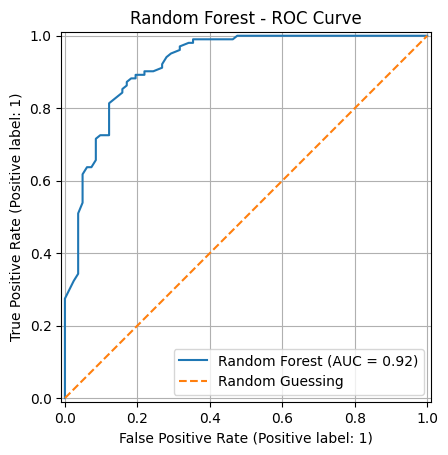

In [13]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Random Forest"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guessing")

plt.title("Random Forest - ROC Curve")
plt.grid(True)
plt.legend()
plt.show()

In [14]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate ROC-AUC for each fold
rf_cv_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Display results
print("ROC-AUC for each fold:", rf_cv_scores)
print("Mean ROC-AUC:", rf_cv_scores.mean())
print("Standard Deviation:", rf_cv_scores.std())

ROC-AUC for each fold: [0.8415558  0.85253283 0.90310513 0.87934905 0.91713431]
Mean ROC-AUC: 0.8787354224617097
Standard Deviation: 0.02876676237366242


In [22]:
joblib.dump(rf_pipeline, "D:/1_Python Programmes/Projects/HDD/models/random_forest_model.pkl")

['D:/1_Python Programmes/Projects/HDD/models/random_forest_model.pkl']

In [29]:
lr_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/logistic_r_model.pkl")
knn_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/heart_disease_knn.pkl")
decision_tree_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/decision_tree_model.pkl")
rf_model = joblib.load("D:/1_Python Programmes/Projects/HDD/models/random_forest_model.pkl")

models = {
    "Logistic Regression": lr_model,
    "KNN": knn_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": rf_model
}

comparison = {}

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    comparison[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Specificity": tn / (tn + fp),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

comparison_df = pd.DataFrame(comparison).T.round(4)

display(comparison_df)

,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC
Logistic Regression,0.8533,0.8505,0.8922,0.8049,0.8708,0.9143
KNN,0.8478,0.8700,0.8529,0.8415,0.8614,0.9030
Decision Tree,0.7554,0.7568,0.8235,0.6707,0.7887,0.7471
Random Forest,0.8533,0.8505,0.8922,0.8049,0.8708,0.9228


In [31]:
comparison_df.to_csv(
    "D:/1_Python Programmes/Projects/HDD/reports/model_comparison.csv",
    index=True,
    index_label="Model"
)
